<a href="https://colab.research.google.com/github/anas2930/ECG-HRV_Analysis-Using-Simple-Technique-Using-Python/blob/main/Clinical_NER_Medical_Transcriptions_(BioBERT)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import transformers
from transformers import pipeline

## Dataframe and Processing

In [ ]:
# Import Dataset
df = pd.read_csv("mtsamples.csv", engine="python", on_bad_lines="skip")

In [ ]:
df.head()

,Unnamed: 0,description,medical_specialty,sample_name,transcription,keywords
0,0,A 23-year-old white female presents with comp...,Allergy / Immunology,Allergic Rhinitis,"SUBJECTIVE:, This 23-year-old white female pr...","allergy / immunology, allergic rhinitis, aller..."
1,1,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 2,"PAST MEDICAL HISTORY:, He has difficulty climb...","bariatrics, laparoscopic gastric bypass, weigh..."
2,2,Consult for laparoscopic gastric bypass.,Bariatrics,Laparoscopic Gastric Bypass Consult - 1,"HISTORY OF PRESENT ILLNESS: , I have seen ABC ...","bariatrics, laparoscopic gastric bypass, heart..."
3,3,2-D M-Mode. Doppler.,Cardiovascular / Pulmonary,2-D Echocardiogram - 1,"2-D M-MODE: , ,1. Left atrial enlargement wit...","cardiovascular / pulmonary, 2-d m-mode, dopple..."
4,4,2-D Echocardiogram,Cardiovascular / Pulmonary,2-D Echocardiogram - 2,1. The left ventricular cavity size and wall ...,"cardiovascular / pulmonary, 2-d, doppler, echo..."


In [ ]:
#Basic Information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4104 entries, 0 to 4103
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Unnamed: 0         4104 non-null   int64 
 1   description        4104 non-null   object
 2   medical_specialty  4104 non-null   object
 3   sample_name        4104 non-null   object
 4   transcription      4072 non-null   object
 5   keywords           3421 non-null   object
dtypes: int64(1), object(5)
memory usage: 192.5+ KB


In [ ]:
df.describe(include='O')

,description,medical_specialty,sample_name,transcription,keywords
count,4072,4072,4072,4072,3389
unique,2254,38,2277,2274,3324
top,Sample progress note - Gen Med.,Surgery,Lumbar Discogram,"PREOPERATIVE DIAGNOSIS: , Low back pain.,POSTO...",
freq,8,1088,5,5,64


In [ ]:
# columns
col=df.columns
print(col)

Index(['description', 'medical_specialty', 'sample_name', 'transcription',
       'keywords'],
      dtype='object')


In [ ]:
# Spot Null and Duplicate Values
print(df.isna().sum(),'\n' ,'Duplicated',df.duplicated(keep=False).sum())

Unnamed: 0             0
description            0
medical_specialty      0
sample_name            0
transcription         32
keywords             683
dtype: int64 
 Duplicated 0


In [ ]:
# Dropping Null Values + Unnecessary cols
df.drop(columns='Unnamed: 0',inplace=True)
df.dropna(subset=['transcription'],inplace=True)
df.isna().sum()

In [ ]:
# Loop over first row
for i in df.columns:
  print(i,':',df[i].iloc[0])
  print('\n')

description :  A 23-year-old white female presents with complaint of allergies.


medical_specialty :  Allergy / Immunology


sample_name :  Allergic Rhinitis 


transcription : SUBJECTIVE:,  This 23-year-old white female presents with complaint of allergies.  She used to have allergies when she lived in Seattle but she thinks they are worse here.  In the past, she has tried Claritin, and Zyrtec.  Both worked for short time but then seemed to lose effectiveness.  She has used Allegra also.  She used that last summer and she began using it again two weeks ago.  It does not appear to be working very well.  She has used over-the-counter sprays but no prescription nasal sprays.  She does have asthma but doest not require daily medication for this and does not think it is flaring up.,MEDICATIONS: , Her only medication currently is Ortho Tri-Cyclen and the Allegra.,ALLERGIES: , She has no known medicine allergies.,OBJECTIVE:,Vitals:  Weight was 130 pounds and blood pressure 124/78.,HEENT:  H

## Import Scicspacify model

In [ ]:
# Demo Code
ner = pipeline("ner", model="d4data/biomedical-ner-all", aggregation_strategy="max")
result = ner("Patient presents with acute chest pain, prescribed 81mg aspirin daily.")
print(result)

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[{'entity_group': 'Detailed_description', 'score': np.float32(0.9968098), 'word': 'acute', 'start': 22, 'end': 27}, {'entity_group': 'Biological_structure', 'score': np.float32(0.9999393), 'word': 'chest', 'start': 28, 'end': 33}, {'entity_group': 'Dosage', 'score': np.float32(0.9993044), 'word': '81mg', 'start': 51, 'end': 55}, {'entity_group': 'Medication', 'score': np.float32(0.9992895), 'word': 'aspirin', 'start': 56, 'end': 63}]


In [ ]:
# sample 0
sample_text = df.iloc[0]["transcription"]
entities = ner(sample_text)


for e in entities:
  if e["score"] > 0.75:  # drop low-confidence noise
    print('>',e["word"], "→", e["entity_group"], f"({e['score']:.2f})",'\n')

> 23 - year - old → Age (0.99) 

> white → Personal_background (1.00) 

> female → Sex (1.00) 

> presents → Clinical_event (1.00) 

> allergies → Disease_disorder (0.84) 

> seattle → Nonbiological_location (0.95) 

> two → Duration (0.89) 

> medication → Medication (0.99) 

> ortho tri - cyclen → Medication (1.00) 

> vitals → Diagnostic_procedure (1.00) 

> weight → Diagnostic_procedure (1.00) 

> 130 pounds → Lab_value (1.00) 

> blood pressure → Diagnostic_procedure (0.99) 

> 124 → Lab_value (0.99) 

> throat → Biological_structure (1.00) 

> erythematous → Sign_symptom (1.00) 

> nasal mucosa → Biological_structure (1.00) 

> erythematous → Sign_symptom (0.99) 

> tms → Diagnostic_procedure (1.00) 

> neck → Biological_structure (0.91) 

> nasonex → Medication (1.00) 

> each nostril → Biological_structure (0.81) 



In [ ]:
# Pipeline over whole Dataset
ner = pipeline("ner", model="d4data/biomedical-ner-all", aggregation_strategy="max", device=0)  # device=0 uses GPU if available

all_results = []

for i, y in enumerate(df['transcription']):
    entities = ner(y)
    for e in entities:
        all_results.append({
            "specialty": df.iloc[i]["medical_specialty"],
            "entity_text": e["word"],
            "entity_type": e["entity_group"],
            "score": e["score"]
        })

Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

ERROR:root:Internal Python error in the inspect module.
Below is the traceback from this internal error.


KeyboardInterrupt



In [ ]:
# List to Dataframe Conversion
results_df = pd.DataFrame(all_results)
results_df.head()

,record_id,specialty,entity_text,entity_type,score
0,0.0,Allergy / Immunology,23 - year - old,Age,0.992029
1,0.0,Allergy / Immunology,white,Personal_background,0.998675
2,0.0,Allergy / Immunology,female,Sex,0.998855
3,0.0,Allergy / Immunology,presents,Clinical_event,0.998992
4,0.0,Allergy / Immunology,allergies,Disease_disorder,0.835233


In [ ]:
# Sorting over Confidence Score
results_df= results_df[results_df['score']> 0.80]

In [ ]:
# top diseases across all specialties
results_df[results_df["entity_type"] == "Disease_disorder"]["entity_text"].value_counts().head(10)

# top medications
results_df[results_df["entity_type"] == "Medication"]["entity_text"].value_counts().head(10)

,count
entity_text,
hernia,140
fracture,114
carcinoma,69
adenocarcinoma,69
squamous cell carcinoma,58
infection,53
cellulitis,49
renal,41
radiculopathy,40


In [ ]:
# most common entity type per specialty
specialty_summary = results_df.groupby(["specialty", "entity_type"]).size().reset_index(name="count")
specialty_summary = specialty_summary.sort_values(["specialty", "count"], ascending=[True, False])

In [ ]:
def top_entities_per_specialty(df, entity_type, n=5):
    subset = df[df["entity_type"] == entity_type]
    return subset.groupby("specialty")["entity_text"].apply(lambda x: x.value_counts().head(n))

top_entities_per_specialty(results_df, "Medication")

specialty                                
Allergy / Immunology  medication              2
                      ortho tri - cyclen      2
                      nasonex                 2
Bariatrics            hydrochlorothiazide     4
                      general anesthesia      2
                                             ..
Urology               antibiotics            32
                      marcaine               26
                      lidocaine              26
                      vicryl                 22
                      antibiotic             14
Name: entity_text, Length: 176, dtype: int64

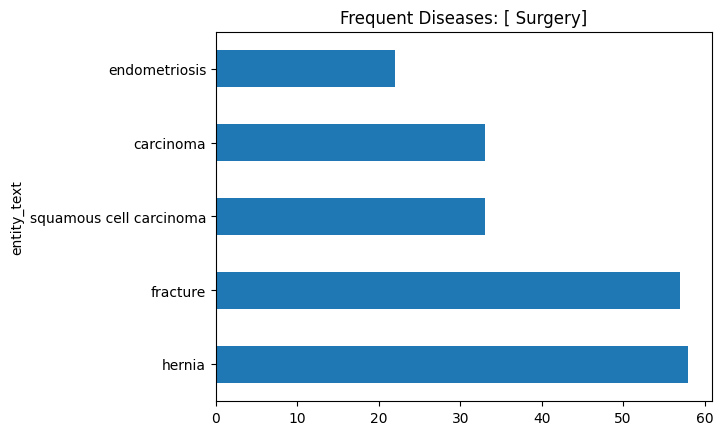

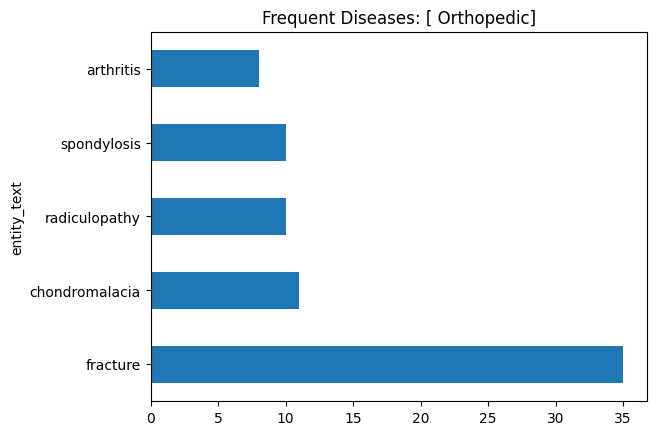

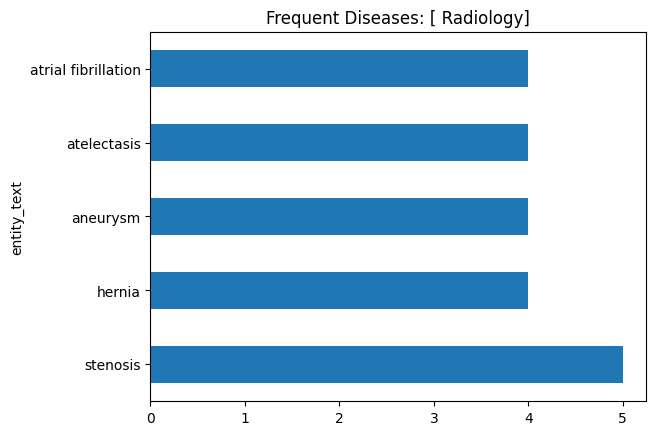

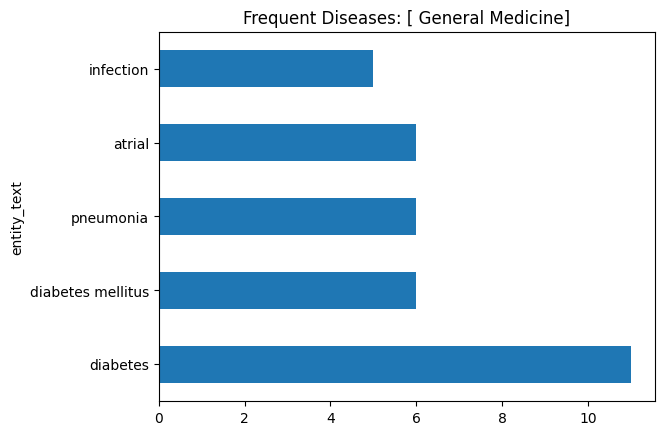

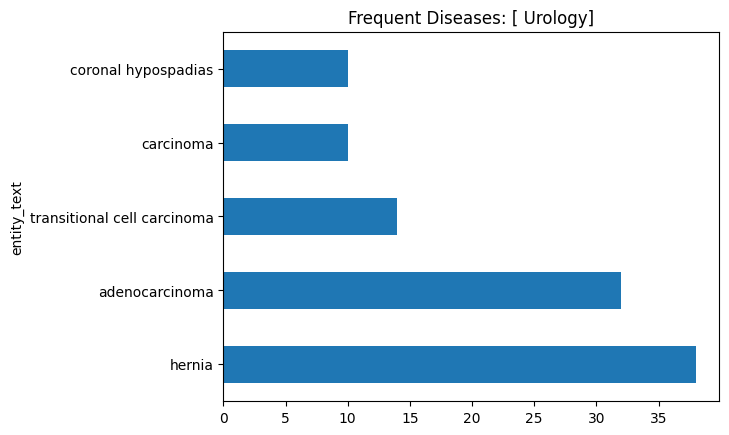

In [ ]:
# Most Frequenct Diseases by Speciality
top_specialties = results_df["specialty"].value_counts().head(5).index
for spec in top_specialties:
    subset = results_df[(results_df["specialty"] == spec) & (results_df["entity_type"] == "Disease_disorder")]
    subset["entity_text"].value_counts().head(5).plot(kind="barh", title=f"Frequent Diseases: [{spec}]")
    plt.show()